# Logistic regression applied to the classification of languages

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import MDS

Data taken from Batagelj, V., Kerzic, D., & Pisanski, T. (1992) Automatic Clustering of Languages. Computational Linguistics, 18(3).

The data correspond to 16 words in 65 languages. I added the linguistic family for each language.

Can we tell if a language is Germanic or Romance looking only at how 16 words are written?

In [2]:
dat = pd.read_csv('words_languages.csv')
dat

,Language,Family,word1,word2,word3,word4,word5,word6,word7,word8,word9,word10,word11,word12,word13,word14,word15,word16
0,Albanian,Albanian,gjithcka,keq,bark,galm,asht,dite,vdes,pi,vesh,ha,ve,sy,ate,peshk,pese,kembe
1,Arabic Tunisian,Semitic,ilkul,xiab,kirsh,akhal,adhum,yuum,met,ushrub,wdhin,akul,adhum,ain,baba,semica,xamsa,sak
2,Bahasa Malaysia,Malayo-Polynesian,semua,jahat,perut,hitam,tulang,hari,mati,minum,telinga,makan,telur,mata,ayah,ikan,lima,kaki
3,Bengali,Indic,sob,kharap,pet,kalo,harh,din,mora,khaoa,kan,khaoa,dim,chokh,baba,mach,panch,pa
4,Berber,Berber,akith,diri,aaboudh,averkan,ighass,as,amath,sew,amazough,atch,thamalalt,thit,vava,ahithiw,khamsa,akajar
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
60,Tamil,Dravidian,ellaam,keduthy,vayiru,karuppu,elumbu,naal,irappu,kuditthal,kaathu,saapiduthal,muttai,kann,appaa,meen,ainthu,kaal
61,Telugu,Dravidian,antha,chedda,kadupu,nalla,yamuka,thinam,chavu,thagu,chevi,thinadam,kuddu,kallu,nanna,chapa,ayithu,kalu
62,Turkish,Turkic,butun,fena,karin,kara,kemik,gun,olmek,icmek,kulak,yemek,yumurta,goz,baba,balik,bes,ayak
63,Ukranian,Slavic,vse,pohane,zhevit,chorne,kistka,den',vmerte,pihte,ukho,yiste,jajtse,oko,bat'ko,rihba,pyat,noha


In [3]:
dat[dat['Language'] == 'Spanish']

,Language,Family,word1,word2,word3,word4,word5,word6,word7,word8,word9,word10,word11,word12,word13,word14,word15,word16
57,Spanish,Romance,todo,mal,vientre,negro,hueso,dia,morir,beber,oreja,comer,huevo,ojo,padre,pez,cinco,pie


In [4]:
dat[['Language', 'Family']].groupby('Family').agg('count')

,Language
Family,
Albanian,1
Baltic,2
Bantu,1
Berber,1
Celtic,2
Dravidian,4
Esperanto,1
Germanic,9
Hellenic,2


## From words to numbers: the Levenshtein distance

The Levenshtein distance between two words is the minimum number of insertions, deletions or substitutions of one character needed to change one word into the other. We divide it by the sum of the lengths of the two words, to get a dissimilarity that does not depend on how long the words are.

In [5]:
def levenshtein(str1, str2):
  d = dict()
  for i in range(len(str1)+1):
     d[i] = dict()
     d[i][0] = i
  for i in range(len(str2)+1):
     d[0][i] = i
  for i in range(1, len(str1)+1):
     for j in range(1, len(str2)+1):
        d[i][j] = min(d[i][j-1]+1, d[i-1][j]+1, d[i-1][j-1]+(not str1[i-1] == str2[j-1]))
  return d[len(str1)][len(str2)]

def disimilar_levenshtein(str1, str2):
    return(levenshtein(str2, str1)/(len(str1) + len(str2)))

disimilar_vect = np.vectorize(disimilar_levenshtein)

In [6]:
examples = [('ovo', 'huevo'), ('ovo', 'uovo'), ('ovo', 'egg'), ('patro', 'padre'), ('patro', 'father')]
pd.DataFrame([(a, b, levenshtein(a, b), round(disimilar_levenshtein(a, b), 3)) for a, b in examples],
             columns=['word 1', 'word 2', 'Levenshtein distance', 'dissimilarity'])

,word 1,word 2,Levenshtein distance,dissimilarity
0,ovo,huevo,3,0.375
1,ovo,uovo,1,0.143
2,ovo,egg,3,0.500
3,patro,padre,2,0.200
4,patro,father,4,0.364


## The data for the model

We use the Germanic and Romance languages. As covariates we take the dissimilarity of each of the 16 words to the same word in Esperanto, a constructed language with roots in both families.

In [7]:
dat_simpl = dat[dat['Family'].isin(['Germanic', 'Romance', 'Esperanto'])]
word_columns = [f'word{i}' for i in range(1, 17)]

base_words = dat_simpl.loc[dat_simpl['Language'] == 'Esperanto', word_columns]
meanings = dat.loc[dat['Language'] == 'English', word_columns].iloc[0].str.replace('to ', '').to_numpy()

pd.DataFrame({'Esperanto': base_words.iloc[0].to_numpy(), 'meaning': meanings}, index=word_columns).T

,word1,word2,word3,word4,word5,word6,word7,word8,word9,word10,word11,word12,word13,word14,word15,word16
Esperanto,cio,malbona,ventro,nigra,osto,tago,morti,trinki,orelo,mangi,ovo,okulo,patro,fiso,kvin,piedo
meaning,all,bad,belly,black,bone,day,die,drink,ear,eat,egg,eye,father,fish,five,foot


In [8]:
languages = dat_simpl[dat_simpl['Family'] != 'Esperanto'].reset_index(drop=True)

X = pd.DataFrame(disimilar_vect(languages[word_columns], base_words), index=languages['Language'], columns=meanings)

# 0 is Romance
# 1 is Germanic
y = languages['Family'].map({'Romance': 0, 'Germanic': 1})
y.index = languages['Language']

X.round(2)

,all,bad,belly,black,bone,day,die,drink,ear,eat,egg,eye,father,fish,five,foot
Language,,,,,,,,,,,,,,,,
Catalan,0.50,0.38,0.45,0.20,0.33,0.57,0.20,0.55,0.18,0.36,0.40,0.38,0.22,0.50,0.38,0.38
Danish,0.50,0.55,0.67,0.44,0.57,0.29,0.55,0.33,0.25,0.54,0.50,0.50,0.40,0.25,0.38,0.50
Dutch,0.67,0.46,0.60,0.40,0.43,0.29,0.50,0.23,0.50,0.56,0.60,0.50,0.40,0.50,0.38,0.44
English,0.50,0.60,0.45,0.50,0.50,0.43,0.36,0.29,0.50,0.55,0.50,0.62,0.36,0.12,0.50,0.56
French,0.57,0.36,0.08,0.33,0.33,0.50,0.27,0.45,0.25,0.18,0.43,0.33,0.33,0.36,0.38,0.11
German,0.57,0.47,0.55,0.50,0.55,0.14,0.50,0.15,0.50,0.50,0.60,0.44,0.30,0.22,0.44,0.56
German Bavarian,0.60,0.47,0.55,0.50,0.50,0.29,0.50,0.55,0.53,0.56,0.33,0.44,0.40,0.30,0.56,0.50
German Swiss 1,0.50,0.50,0.60,0.50,0.55,0.14,0.50,0.08,0.50,0.50,0.60,0.38,0.36,0.22,0.50,0.40
German Swiss 2,0.62,0.50,0.60,0.50,0.55,0.29,0.50,0.17,0.50,0.50,0.60,0.38,0.36,0.22,0.50,0.40


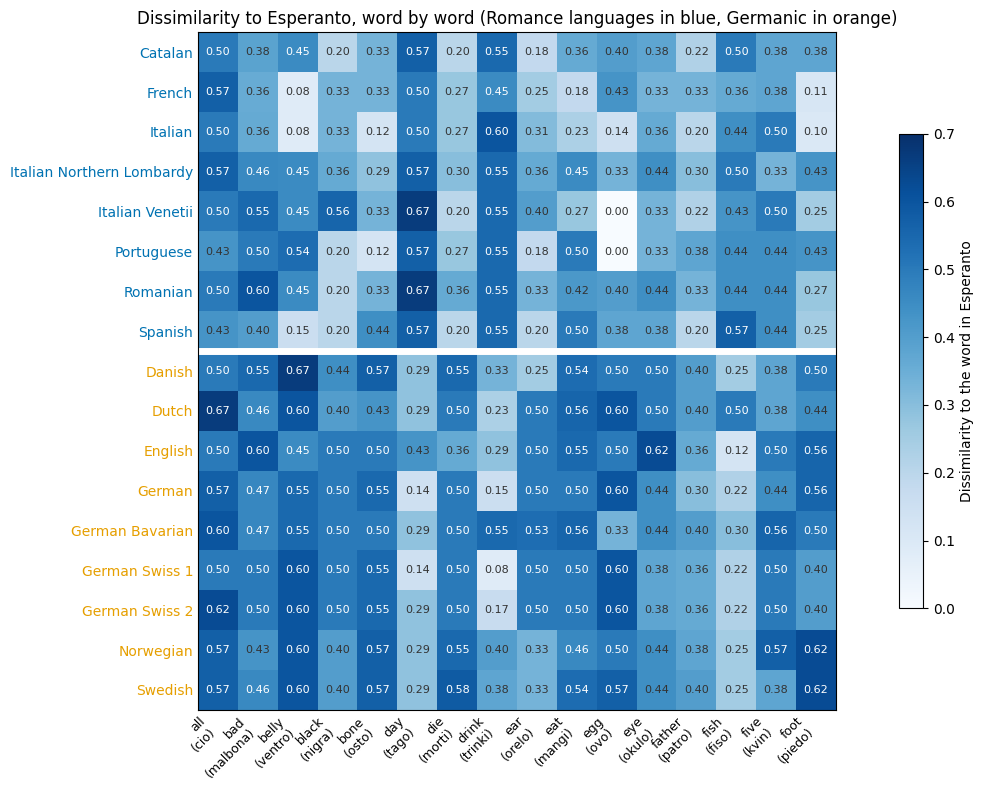

In [9]:
family_colors = {'Romance': '#0072B2', 'Germanic': '#E69F00'}

order = np.argsort(y.to_numpy(), kind='stable')
fig, ax = plt.subplots(figsize=(13, 8))
im = ax.imshow(X.to_numpy()[order], cmap='Blues', vmin=0, vmax=0.7)
for i, row in enumerate(order):
    for j in range(16):
        ax.text(j, i, f'{X.iloc[row, j]:.2f}', ha='center', va='center', fontsize=8,
                color='white' if X.iloc[row, j] > 0.45 else '#333333')
ax.set_xticks(range(16), [f'{m}\n({e})' for m, e in zip(meanings, base_words.iloc[0])], fontsize=9, rotation=45, ha='right')
ax.set_yticks(range(len(order)), X.index[order])
for tick, row in zip(ax.get_yticklabels(), order):
    tick.set_color(family_colors[languages['Family'][row]])
ax.axhline((y == 0).sum()-0.5, color='white', lw=5)
ax.tick_params(length=0)
fig.colorbar(im, ax=ax, label='Dissimilarity to the word in Esperanto', shrink=0.7)
ax.set_title('Dissimilarity to Esperanto, word by word (Romance languages in blue, Germanic in orange)')
plt.tight_layout()

Some words almost separate the families by themselves: *day* (tago) and *drink* (trinki) are close to the Germanic words, *belly* (ventro) to the Romance ones.

## Logistic regression

Let's take out Spanish and English from the training data set

In [10]:
test_languages = ['English', 'Spanish']

# Creation of training and testing data set
X_train = X.drop(test_languages)
X_test = X.loc[test_languages]

y_train = y.drop(test_languages)
y_test = y[test_languages]

print('Training languages:', len(X_train), ' Covariates:', X_train.shape[1])

Training languages: 15  Covariates: 16


There are more covariates (16) than training languages (15), so the two families can be separated perfectly and the maximum likelihood estimators do not exist. We use a very small penalty (`C` is the inverse of the penalty) to have a well defined solution.

In [11]:
# Using LogisticRegression
logreg = LogisticRegression(C=1e4, fit_intercept=False, max_iter=10000)
logreg.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,10000.0
,fit_intercept,False
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,10000
,multi_class,'deprecated'


In [12]:
pd.DataFrame({'family': y_train.map({0: 'Romance', 1: 'Germanic'}),
              'observed': y_train,
              'predicted': logreg.predict(X_train)})

,family,observed,predicted
Language,,,
Catalan,Romance,0,0
Danish,Germanic,1,1
Dutch,Germanic,1,1
French,Romance,0,0
German,Germanic,1,1
German Bavarian,Germanic,1,1
German Swiss 1,Germanic,1,1
German Swiss 2,Germanic,1,1
Italian,Romance,0,0


In [13]:
pd.DataFrame({'family': y_test.map({0: 'Romance', 1: 'Germanic'}),
              'observed': y_test,
              'predicted': logreg.predict(X_test),
              'probability of Germanic': logreg.predict_proba(X_test)[:, 1].round(4)})

,family,observed,predicted,probability of Germanic
Language,,,,
English,Germanic,1,1,0.9981
Spanish,Romance,0,0,0.0002


### Which words matter?

A positive coefficient means that the further the word is from Esperanto, the more likely the language is Germanic.

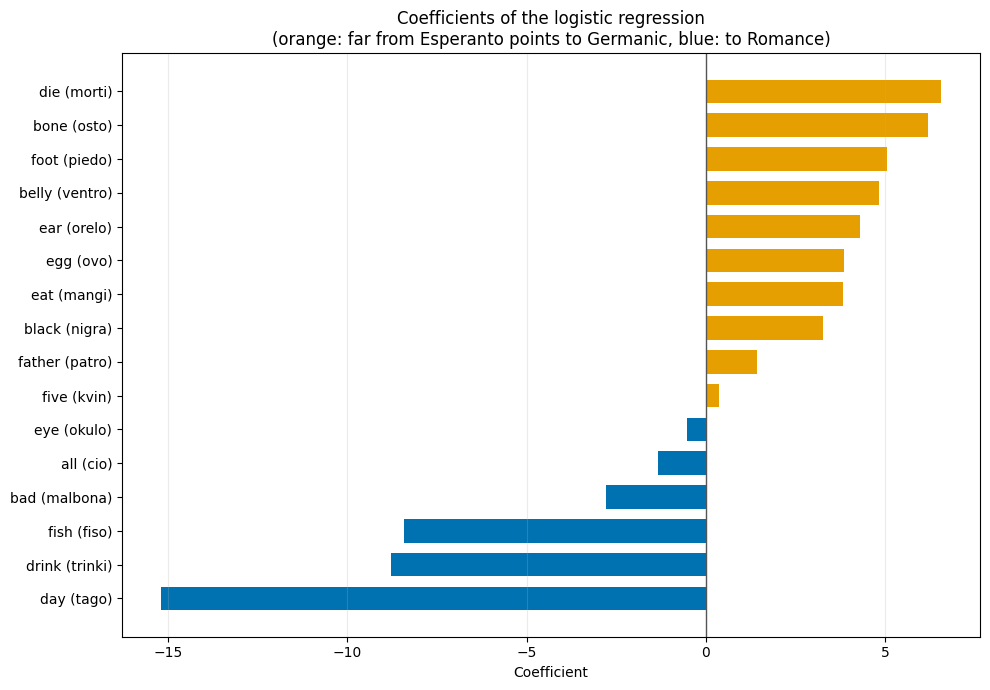

In [14]:
coef = pd.Series(logreg.coef_[0], index=[f'{m} ({e})' for m, e in zip(meanings, base_words.iloc[0])]).sort_values()

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(coef.index, coef, color=[family_colors['Germanic'] if c > 0 else family_colors['Romance'] for c in coef],
        height=0.7)
ax.axvline(0, color='#555555', lw=1)
ax.set_xlabel('Coefficient')
ax.set_title('Coefficients of the logistic regression\n(orange: far from Esperanto points to Germanic, blue: to Romance)')
ax.grid(True, axis='x', alpha=0.25)
plt.tight_layout()

## Let's plot using MDS

Multidimensional scaling places the languages in the plane trying to keep the distances between their 16 dissimilarities. The two families form two groups, and the two testing languages fall in the right one.

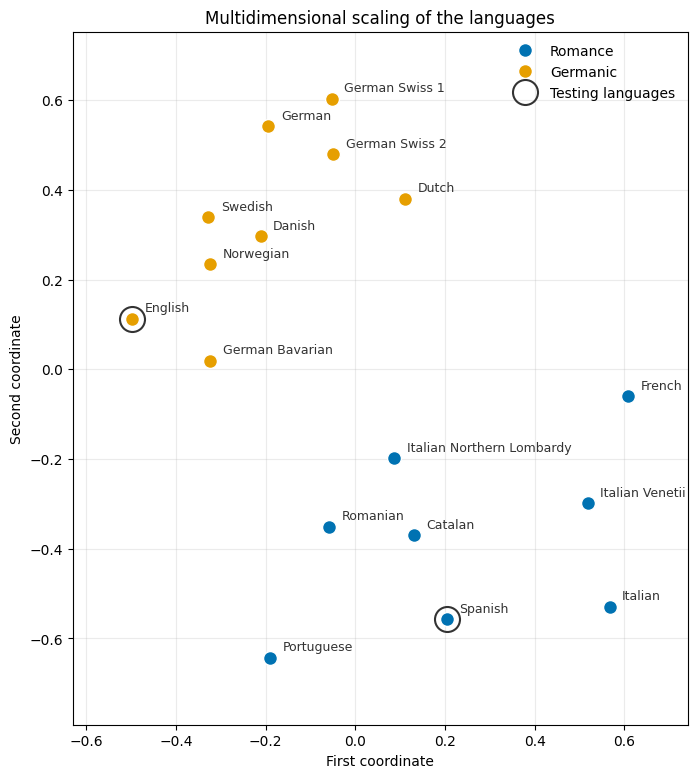

In [15]:
mds_model = MDS(n_components=2, n_init=4, random_state=111)
X_mds = mds_model.fit_transform(X.to_numpy())

fig, ax = plt.subplots(figsize=(11, 9))
for family, color in family_colors.items():
    mask = (languages['Family'] == family).to_numpy()
    ax.plot(X_mds[mask, 0], X_mds[mask, 1], 'o', color=color, markersize=10, markeredgecolor='white',
            markeredgewidth=1, label=family)
is_test = X.index.isin(test_languages)
ax.plot(X_mds[is_test, 0], X_mds[is_test, 1], 'o', markersize=18, markerfacecolor='none', markeredgecolor='#333333',
        markeredgewidth=1.5, label='Testing languages')
for name, (a, b) in zip(X.index, X_mds):
    ax.annotate(name, (a, b), xytext=(9, 5), textcoords='offset points', fontsize=9, color='#333333')
ax.set_aspect('equal')
ax.margins(0.12)
ax.set_xlabel('First coordinate')
ax.set_ylabel('Second coordinate')
ax.set_title('Multidimensional scaling of the languages')
ax.legend(loc='best', frameon=False)
ax.grid(True, alpha=0.25)